# Correlación, significancia y causalidad en la regresión múltiple

**Universidad Politécnica del Bicentenario** · Econometría

---

**Contenido**

1. Introducción: lo que la significancia dice y lo que no dice
2. Conceptos clave: confusores, causalidad inversa y coincidencias
3. Caso de ejemplo: ¿la publicidad realmente vende más helado?
   - 3.1 Datos y exploración
   - 3.2 El modelo simple: una conclusión tentadora
   - 3.3 El modelo múltiple: aparece el confusor
   - 3.4 ¿Por qué cambió el coeficiente? Sesgo por variable omitida
   - 3.5 El experimento: la herramienta más sólida para hablar de causalidad
   - 3.6 Pronosticar no es lo mismo que decidir
4. Conclusiones y preguntas para evaluar una afirmación causal
5. Ejercicio: ¿más vendedores causan más ventas?
6. Solución del ejercicio (para el profesor)

## 1. Introducción: lo que la significancia dice y lo que no dice

En el cuaderno anterior vimos cómo plantear las pruebas de hipótesis de la regresión múltiple:

- **Prueba F:** $H_0:\ \beta_1=\dots=\beta_k=0$ (el modelo en conjunto no aporta).
- **Prueba t:** $H_0:\ \beta_j=0$ (la variable $x_j$ no aporta, dadas las demás).

Cuando el valor-p es menor que $\alpha$ rechazamos $H_0$ y decimos que la variable es **estadísticamente significativa**. Es muy tentador leer eso como *"$x_j$ provoca cambios en $y$"*. **Esa lectura es incorrecta.**

> **La significancia estadística responde a:** *¿es probable que esta relación en mis datos sea solo casualidad?*
>
> **No responde a:** *¿por qué existe esa relación?* ¿$x$ causa $y$?, ¿$y$ causa $x$?, ¿o hay un tercer factor que mueve a ambas?

Un ejemplo clásico: en las ciudades costeras, los meses con más ventas de helado son también los meses con más personas ahogadas. La relación es estadísticamente significativa y se repite año con año. Pero **comer helado no provoca ahogamientos**: el calor lleva a la gente tanto a comprar helado como a meterse al agua. El calor es el **factor oculto** (o *confusor*) que genera la asociación.

En los negocios el mismo error es costoso: invertimos más en publicidad, contratamos más vendedores o abrimos más sucursales porque *"los datos muestran que se relaciona con las ventas"*, y después los resultados no llegan.

En este cuaderno veremos con un caso simulado cómo un coeficiente significativo puede ser engañoso, cómo la regresión múltiple ayuda a detectarlo (y sus límites), y qué hace falta para respaldar una afirmación causal.

## 2. Conceptos clave

### 2.1 Tres razones por las que dos variables pueden estar relacionadas sin que una cause a la otra

| Explicación | Qué ocurre | Ejemplo de negocio |
|-------------|-----------|--------------------|
| **Variable de confusión** (factor oculto) | Una tercera variable $z$ afecta tanto a $x$ como a $y$ | La temporada alta aumenta a la vez el gasto en publicidad y las ventas |
| **Causalidad inversa** | En realidad $y$ causa $x$, no al revés | Se contratan más vendedores *porque* las ventas ya subieron |
| **Coincidencia** (relación espuria) | Dos series comparten una tendencia por azar, o se probaron tantas variables que alguna salió significativa | Dos series que crecen con los años sin ninguna conexión real |

### 2.2 Sesgo por variable omitida

Supongamos que el modelo verdadero es

$$
y = \beta_0 + \beta_1 x + \beta_2 z + \varepsilon
$$

pero ajustamos solo $y$ contra $x$, **omitiendo** $z$. El coeficiente de $x$ en el modelo simple, $b_{simple}$, cumple (es una identidad algebraica de MCO):

$$
b_{simple} \;=\; \hat\beta_1 \;+\; \hat\beta_2\cdot\delta
$$

donde $\hat\beta_1$ y $\hat\beta_2$ son los coeficientes del modelo múltiple y $\delta$ es la pendiente de regresar $z$ sobre $x$. Es decir, el modelo simple **mezcla** el efecto propio de $x$ con el efecto de $z$ que "viaja" junto con $x$. El sesgo desaparece solo si $\hat\beta_2=0$ ($z$ no influye en $y$) o si $\delta=0$ ($z$ no está relacionada con $x$).

### 2.3 Lo que la regresión múltiple sí hace... y lo que no

Cuando agregamos $z$ al modelo, el coeficiente de $x$ se interpreta *"manteniendo constante $z$"*. Por eso la regresión múltiple **controla** por los confusores **que están en el modelo**. Pero:

- No controla por los confusores que **no medimos** o **no incluimos**.
- No resuelve la causalidad inversa.
- No evita las coincidencias.

Por eso un coeficiente significativo en una regresión múltiple sigue siendo, en principio, una **asociación**.

### 2.4 ¿Qué respalda una afirmación causal?

1. **Experimento aleatorio:** asignar $x$ al azar rompe cualquier vínculo con los factores ocultos. Es la herramienta más sólida.
2. **Temporalidad:** la causa debe ocurrir antes que el efecto.
3. **Mecanismo plausible:** una explicación de negocio que tenga sentido.
4. **Control de confusores relevantes** y resultados que se mantienen al cambiar el modelo.
5. **Consistencia:** la relación se repite en otros periodos, tiendas o mercados.

### 2.5 Una aclaración de vocabulario para esta materia

En Pronósticos se llama **modelo causal** a un modelo que usa variables explicativas externas (publicidad, precio, temperatura...) para pronosticar, en contraste con un modelo de **series de tiempo** que solo usa el histórico de la propia variable. Ese uso del término **no garantiza** que la relación sea causal en sentido estricto. Para *pronosticar* basta con que la variable ayude a predecir bien; para *decidir* ("si aumento $x$, ¿qué le pasa a $y$?") sí necesitamos pensar en causalidad.

## 3. Caso de ejemplo: ¿la publicidad realmente vende más helado?

**Situación.** *Helados del Bajío* (heladería ficticia) tiene 48 meses de información. El gerente observa que en los meses en que gasta más en publicidad, las ventas son más altas, y está pensando en **duplicar el presupuesto de publicidad** para el siguiente año.

| Variable | Descripción | Unidades |
|----------|-------------|----------|
| `ventas` | Ventas del mes ($y$) | miles de pesos |
| `publicidad` | Gasto en publicidad del mes | miles de pesos |
| `temperatura` | Temperatura promedio del mes | °C |

> **Nota:** los datos son **simulados** con semilla fija. En la simulación la publicidad **no tiene ningún efecto sobre las ventas** (su coeficiente verdadero es 0); lo que sí influye es la temperatura. El gerente, sin saberlo, programa más publicidad en los meses de calor. En la práctica nunca conocemos la "verdad", pero aquí sí, y eso nos permite ver si el análisis nos engaña.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Markdown, display

# Colores: vino para los datos, gris para referencias, azul para ajustes/alternativas
VINO, GRIS, AZUL, TINTA = "#9E1B31", "#8A8A8A", "#2B6CB0", "#1A1A1A"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "text.color": TINTA,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10, "axes.labelcolor": TINTA,
    "axes.edgecolor": GRIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E4E2DE", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TINTA, "ytick.color": TINTA,
})
pd.options.display.float_format = "{:,.4f}".format
ALFA = 0.05   # nivel de significancia

def pesos(x):   # el $ lleva barra para que Markdown no lo confunda con una fórmula
    return f"\\${x:,.0f}"

### 3.1 Datos y exploración

Generamos 48 meses de datos y, además, 24 meses adicionales de un **experimento** que usaremos en la sección 3.5 (meses en los que la publicidad se asignó al azar).

In [ ]:
rng = np.random.default_rng(23)
n = 48
mes = np.arange(n) % 12                                              # 0 = enero ... 11 = diciembre

temperatura = (24 + 7*np.sin(2*np.pi*(mes - 3)/12) + rng.normal(0, 1.5, n)).round(1)   # °C
publicidad  = (26 + 1.2*(temperatura - 24) + rng.normal(0, 4.0, n)).round(1)           # el gerente gasta más cuando hace calor
ruido       = rng.normal(0, 25, n)
VERDADEROS  = {"Intercepto": 120, "publicidad": 0.0, "temperatura": 9.0}
ventas      = (120 + 9*temperatura + 0*publicidad + ruido).round(1)                    # la publicidad NO influye

df = pd.DataFrame({"ventas": ventas, "publicidad": publicidad, "temperatura": temperatura})
df.index = pd.period_range("2022-01", periods=n, freq="M")
df.index.name = "mes"

# Experimento: 24 meses en los que la publicidad se asigna al azar (independiente de la temperatura)
m_exp = 24
publi_e = rng.uniform(10, 40, m_exp).round(1)
temp_e  = (24 + 7*np.sin(2*np.pi*(np.arange(m_exp) % 12 - 3)/12) + rng.normal(0, 1.5, m_exp)).round(1)
vent_e  = (120 + 9*temp_e + rng.normal(0, 25, m_exp)).round(1)
exp = pd.DataFrame({"ventas": vent_e, "publicidad": publi_e, "temperatura": temp_e})

df.head(8)

,ventas,publicidad,temperatura
mes,,,
2022-01,261.0000,22.7000,17.8000
2022-02,248.7000,13.8000,18.3000
2022-03,291.9000,20.1000,20.4000
2022-04,312.9000,22.7000,20.5000
2022-05,353.4000,24.5000,28.1000
2022-06,323.0000,24.5000,26.9000
2022-07,437.7000,29.3000,32.4000
2022-08,389.7000,35.5000,31.0000


In [ ]:
df.describe().round(2)

,ventas,publicidad,temperatura
count,48.0000,48.0000,48.0000
mean,337.2500,25.0000,23.9800
std,55.1800,8.0300,5.2800
min,248.7000,5.3000,15.0000
25%,292.2000,19.9000,19.4000
50%,340.2000,24.5500,23.6500
75%,381.6000,30.0800,28.7200
max,441.9000,42.9000,34.3000


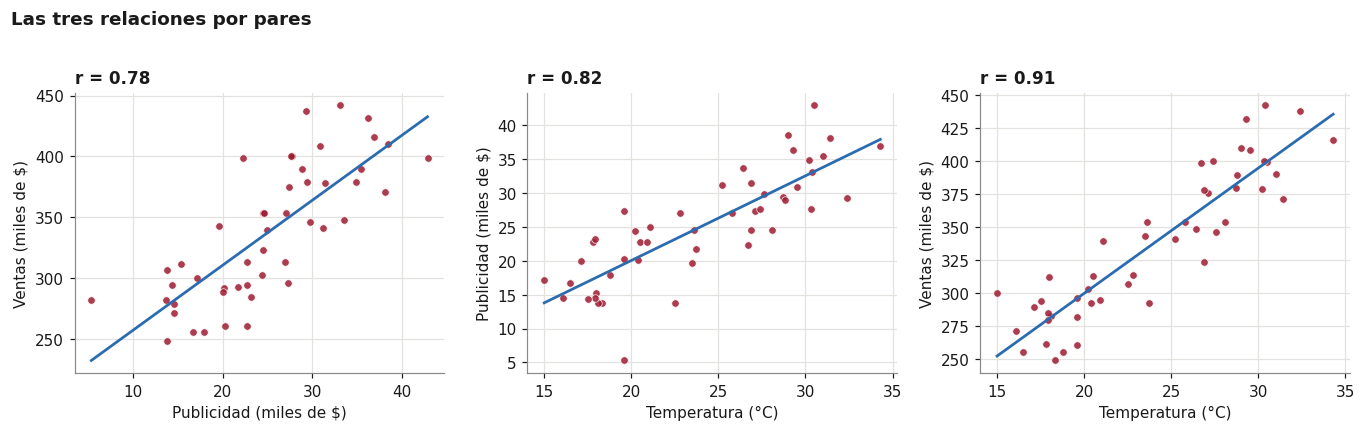

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))

for ax, (xcol, ycol, xl, yl) in zip(axes, [
        ("publicidad", "ventas", "Publicidad (miles de $)", "Ventas (miles de $)"),
        ("temperatura", "publicidad", "Temperatura (°C)", "Publicidad (miles de $)"),
        ("temperatura", "ventas", "Temperatura (°C)", "Ventas (miles de $)")]):
    ax.scatter(df[xcol], df[ycol], s=24, color=VINO, alpha=0.85, edgecolor="white", linewidth=0.5)
    b1, b0 = np.polyfit(df[xcol], df[ycol], 1)
    xs = np.linspace(df[xcol].min(), df[xcol].max(), 50)
    ax.plot(xs, b0 + b1*xs, color=AZUL, lw=1.8)
    ax.set_title(f"r = {df[xcol].corr(df[ycol]):.2f}", loc="left")
    ax.set_xlabel(xl); ax.set_ylabel(yl)

fig.suptitle("Las tres relaciones por pares", x=0.01, ha="left", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
r_pv, r_pt, r_vt = df.publicidad.corr(df.ventas), df.publicidad.corr(df.temperatura), df.ventas.corr(df.temperatura)
display(Markdown(
    f"**Qué observamos.** La publicidad se relaciona fuertemente con las ventas (r = {r_pv:.2f}). Pero la publicidad "
    f"también se relaciona fuertemente con la temperatura (r = {r_pt:.2f}), y la temperatura con las ventas "
    f"(r = {r_vt:.2f}). Las tres variables se mueven juntas: ¿quién está haciendo qué?"
))

**Qué observamos.** La publicidad se relaciona fuertemente con las ventas (r = 0.78). Pero la publicidad también se relaciona fuertemente con la temperatura (r = 0.82), y la temperatura con las ventas (r = 0.91). Las tres variables se mueven juntas: ¿quién está haciendo qué?

### 3.2 El modelo simple: una conclusión tentadora

Ajustamos lo que haría el gerente: regresar las ventas solo sobre la publicidad.

$$ ventas_i = \beta_0 + \beta_1\, publicidad_i + \varepsilon_i $$

In [ ]:
m_simple = smf.ols("ventas ~ publicidad", data=df).fit()
print(m_simple.summary().tables[1])
print(f"\nEstadístico F = {m_simple.fvalue:.1f}   valor-p de F = {m_simple.f_pvalue:.2e}   R² = {m_simple.rsquared:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    204.0962     16.786     12.158      0.000     170.307     237.886
publicidad     5.3261      0.640      8.323      0.000       4.038       6.614

Estadístico F = 69.3   valor-p de F = 9.92e-11   R² = 0.601


In [ ]:
b_s, p_s = m_simple.params["publicidad"], m_simple.pvalues["publicidad"]
display(Markdown(
    f"**Lectura ingenua.** El coeficiente de `publicidad` es {b_s:.2f} y su valor-p es {p_s:.1e}, muy inferior a α = {ALFA}. "
    f"Se rechaza H₀: β₁ = 0. El gerente concluiría: *«cada " + pesos(1000) + " adicionales en publicidad aumentan las ventas en "
    f"{pesos(b_s*1000)}»* y que duplicar el presupuesto es una gran idea.\n\n"
    f"El modelo es **estadísticamente significativo**, y aun así esa conclusión es incorrecta."
))

**Lectura ingenua.** El coeficiente de `publicidad` es 5.33 y su valor-p es 9.9e-11, muy inferior a α = 0.05. Se rechaza H₀: β₁ = 0. El gerente concluiría: *«cada \$1,000 adicionales en publicidad aumentan las ventas en \$5,326»* y que duplicar el presupuesto es una gran idea.

El modelo es **estadísticamente significativo**, y aun así esa conclusión es incorrecta.

### 3.3 El modelo múltiple: aparece el confusor

Ahora incluimos la temperatura. Cada coeficiente se interpreta *manteniendo constante la otra variable*:

$$ ventas_i = \beta_0 + \beta_1\, publicidad_i + \beta_2\, temperatura_i + \varepsilon_i $$

In [ ]:
m_mult = smf.ols("ventas ~ publicidad + temperatura", data=df).fit()
print(m_mult.summary().tables[1])
print(f"\nEstadístico F = {m_mult.fvalue:.1f}   valor-p de F = {m_mult.f_pvalue:.2e}   "
      f"R² = {m_mult.rsquared:.3f}   R² ajustado = {m_mult.rsquared_adj:.3f}")

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     112.7747     16.331      6.906      0.000      79.882     145.667
publicidad      0.6400      0.745      0.859      0.395      -0.860       2.140
temperatura     8.6947      1.134      7.668      0.000       6.411      10.978

Estadístico F = 107.6   valor-p de F = 7.17e-18   R² = 0.827   R² ajustado = 0.819


In [ ]:
b_m, p_m = m_mult.params["publicidad"], m_mult.pvalues["publicidad"]
b_t, p_t = m_mult.params["temperatura"], m_mult.pvalues["temperatura"]
display(Markdown(
    f"**Lectura correcta.** Al controlar por la temperatura, el coeficiente de la publicidad cae de {b_s:.2f} a {b_m:.2f} "
    f"y su valor-p sube a {p_m:.2f} (mayor que α = {ALFA}): **ya no se rechaza H₀**, no hay evidencia de que la "
    f"publicidad aporte una vez que consideramos la temperatura. En cambio, la temperatura sí es significativa "
    f"(coeficiente {b_t:.2f}, valor-p = {p_t:.1e}): cada grado adicional se asocia con {pesos(b_t*1000)} más de ventas.\n\n"
    f"La prueba F global sigue siendo significativa, porque el modelo *en conjunto* sí explica las ventas "
    f"(por la temperatura). Recordemos: **F significativa solo dice que alguna variable aporta, no cuál ni por qué.**"
))

**Lectura correcta.** Al controlar por la temperatura, el coeficiente de la publicidad cae de 5.33 a 0.64 y su valor-p sube a 0.39 (mayor que α = 0.05): **ya no se rechaza H₀**, no hay evidencia de que la publicidad aporte una vez que consideramos la temperatura. En cambio, la temperatura sí es significativa (coeficiente 8.69, valor-p = 1.1e-09): cada grado adicional se asocia con \$8,695 más de ventas.

La prueba F global sigue siendo significativa, porque el modelo *en conjunto* sí explica las ventas (por la temperatura). Recordemos: **F significativa solo dice que alguna variable aporta, no cuál ni por qué.**

In [ ]:
# Comparación lado a lado del coeficiente de la publicidad (valor verdadero = 0)
def fila(modelo, nombre):
    ic = modelo.conf_int().loc["publicidad"]
    return {"Modelo": nombre, "Coef. publicidad": modelo.params["publicidad"],
            "Error estándar": modelo.bse["publicidad"], "IC 95% inf.": ic[0], "IC 95% sup.": ic[1],
            "Valor-p": modelo.pvalues["publicidad"]}

m_exper = smf.ols("ventas ~ publicidad", data=exp).fit()
tabla = pd.DataFrame([fila(m_simple, "Simple (sin temperatura)"),
                      fila(m_mult, "Múltiple (con temperatura)")]).set_index("Modelo")
tabla.round(4)

,Coef. publicidad,Error estándar,IC 95% inf.,IC 95% sup.,Valor-p
Modelo,,,,,
Simple (sin temperatura),5.3261,0.6399,4.0380,6.6141,0.0000
Múltiple (con temperatura),0.6400,0.7449,-0.8604,2.1404,0.3948


### 3.4 ¿Por qué cambió el coeficiente? Sesgo por variable omitida

La identidad de la sección 2.2 explica el cambio: el coeficiente del modelo simple es el efecto propio de la publicidad **más** el efecto de la temperatura que "viaja" con la publicidad. Lo comprobamos numéricamente:

In [ ]:
# delta = pendiente de regresar la temperatura sobre la publicidad
delta = smf.ols("temperatura ~ publicidad", data=df).fit().params["publicidad"]

b_publi_mult = m_mult.params["publicidad"]
b_temp_mult  = m_mult.params["temperatura"]
reconstruido = b_publi_mult + b_temp_mult * delta

tabla_sesgo = pd.DataFrame({
    "Concepto": ["Coef. publicidad, modelo múltiple (efecto propio)",
                 "Coef. temperatura, modelo múltiple",
                 "δ: pendiente de temperatura sobre publicidad",
                 "Efecto propio + (coef. temperatura × δ)",
                 "Coef. publicidad, modelo simple"],
    "Valor": [b_publi_mult, b_temp_mult, delta, reconstruido, m_simple.params["publicidad"]]
}).set_index("Concepto")
display(tabla_sesgo.round(4))
print("¿La identidad se cumple?", np.isclose(reconstruido, m_simple.params["publicidad"]))

,Valor
Concepto,
"Coef. publicidad, modelo múltiple (efecto propio)",0.6400
"Coef. temperatura, modelo múltiple",8.6947
δ: pendiente de temperatura sobre publicidad,0.5390
Efecto propio + (coef. temperatura × δ),5.3261
"Coef. publicidad, modelo simple",5.3261


¿La identidad se cumple? True


In [ ]:
sesgo = m_simple.params["publicidad"] - b_publi_mult
display(Markdown(
    f"Casi todo el coeficiente del modelo simple ({m_simple.params['publicidad']:.2f}) proviene de la temperatura "
    f"({b_temp_mult:.2f} × {delta:.2f} = {b_temp_mult*delta:.2f}); el efecto propio de la publicidad es solo {b_publi_mult:.2f}. "
    f"El **sesgo por variable omitida** es de {sesgo:.2f} unidades."
))

Casi todo el coeficiente del modelo simple (5.33) proviene de la temperatura (8.69 × 0.54 = 4.69); el efecto propio de la publicidad es solo 0.64. El **sesgo por variable omitida** es de 4.69 unidades.

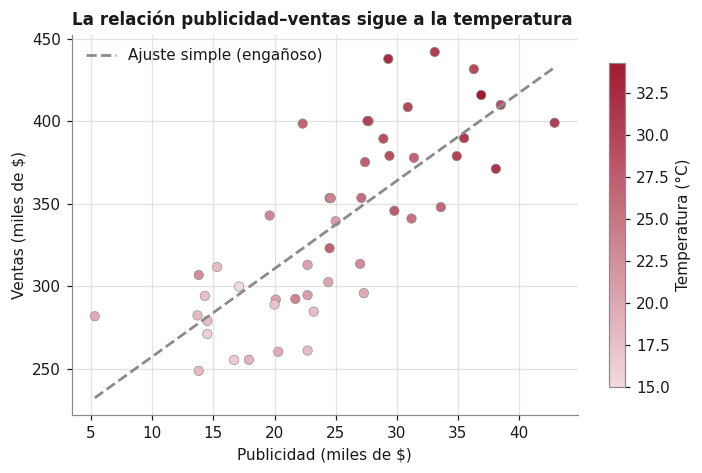

In [ ]:
# Visualización: los mismos puntos, coloreados por la temperatura del mes (más oscuro = más calor)
cmap_t = LinearSegmentedColormap.from_list("calor", ["#F3D9DE", VINO])

fig, ax = plt.subplots(figsize=(6.6, 4.4))
sc = ax.scatter(df["publicidad"], df["ventas"], c=df["temperatura"], cmap=cmap_t, s=38,
                edgecolor=GRIS, linewidth=0.4)
xs = np.linspace(df["publicidad"].min(), df["publicidad"].max(), 50)
ax.plot(xs, m_simple.params["Intercept"] + m_simple.params["publicidad"]*xs, color=GRIS, lw=1.8, ls="--",
        label="Ajuste simple (engañoso)")
ax.set_xlabel("Publicidad (miles de $)"); ax.set_ylabel("Ventas (miles de $)")
ax.set_title("La relación publicidad–ventas sigue a la temperatura", loc="left")
cb = fig.colorbar(sc, ax=ax, shrink=0.85); cb.set_label("Temperatura (°C)")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

Los puntos más oscuros (meses calurosos) están arriba y a la derecha; los claros (meses fríos), abajo y a la izquierda. La publicidad "acompaña" a la temperatura, y por eso parece explicar las ventas.

### 3.5 El experimento: la herramienta más sólida para hablar de causalidad

Imaginemos que la heladería decide hacer una prueba durante 24 meses: **la publicidad de cada mes se sortea al azar** (sin importar la temperatura). Al asignar $x$ aleatoriamente, la publicidad ya no puede estar relacionada con la temperatura ni con ningún otro factor oculto, de modo que cualquier relación con las ventas sí tendría que ser causal.

In [ ]:
print("Correlación publicidad–temperatura en el experimento:", round(exp.publicidad.corr(exp.temperatura), 2))
print("Correlación publicidad–temperatura en los datos observacionales:", round(df.publicidad.corr(df.temperatura), 2))
print()
print(m_exper.summary().tables[1])

Correlación publicidad–temperatura en el experimento: -0.22
Correlación publicidad–temperatura en los datos observacionales: 0.82

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    332.9849     35.666      9.336      0.000     259.019     406.951
publicidad    -0.0195      1.461     -0.013      0.989      -3.050       3.011


,Coef. publicidad,Error estándar,IC 95% inf.,IC 95% sup.,Valor-p
Modelo,,,,,
"Observacional, simple (sin temperatura)",5.3261,0.6399,4.0380,6.6141,0.0000
"Observacional, múltiple (con temperatura)",0.6400,0.7449,-0.8604,2.1404,0.3948
Experimento (publicidad al azar),-0.0195,1.4611,-3.0497,3.0106,0.9895


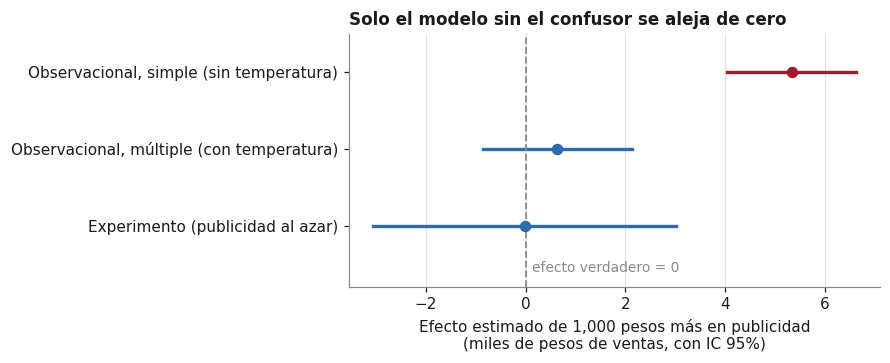

In [ ]:
tabla = pd.DataFrame([fila(m_simple, "Observacional, simple (sin temperatura)"),
                      fila(m_mult, "Observacional, múltiple (con temperatura)"),
                      fila(m_exper, "Experimento (publicidad al azar)")]).set_index("Modelo")
display(tabla.round(4))

# Gráfica de coeficientes con intervalos de confianza
fig, ax = plt.subplots(figsize=(8.2, 3.4))
y_pos = np.arange(len(tabla))[::-1]
colores = [VINO, AZUL, AZUL]
for yp, (nombre, fila_), col in zip(y_pos, tabla.iterrows(), colores):
    ax.plot([fila_["IC 95% inf."], fila_["IC 95% sup."]], [yp, yp], color=col, lw=2.2)
    ax.scatter(fila_["Coef. publicidad"], yp, color=col, s=42, zorder=3)
ax.axvline(0, color=GRIS, ls="--", lw=1.2)
ax.text(0.12, -0.55, "efecto verdadero = 0", color=GRIS, fontsize=9, va="center")
ax.set_ylim(-0.8, 2.5)
ax.set_yticks(y_pos); ax.set_yticklabels(tabla.index)
ax.set_xlabel("Efecto estimado de 1,000 pesos más en publicidad\n(miles de pesos de ventas, con IC 95%)")
ax.set_title("Solo el modelo sin el confusor se aleja de cero", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [ ]:
display(Markdown(
    f"En el experimento, el coeficiente de la publicidad es {m_exper.params['publicidad']:.2f} con valor-p = "
    f"{m_exper.pvalues['publicidad']:.2f}: **no hay efecto detectable**, igual que en el modelo múltiple. "
    f"Los dos análisis que cuidaron al confusor coinciden con la verdad (0); el análisis que lo ignoró nos habría "
    f"hecho gastar de más.\n\n"
    f"*Precaución:* la regresión múltiple funcionó aquí porque **medimos** la temperatura. Si el confusor no se hubiera "
    f"medido, no habría forma de corregirlo con el modelo; el experimento sí lo habría logrado."
))

En el experimento, el coeficiente de la publicidad es -0.02 con valor-p = 0.99: **no hay efecto detectable**, igual que en el modelo múltiple. Los dos análisis que cuidaron al confusor coinciden con la verdad (0); el análisis que lo ignoró nos habría hecho gastar de más.

*Precaución:* la regresión múltiple funcionó aquí porque **medimos** la temperatura. Si el confusor no se hubiera medido, no habría forma de corregirlo con el modelo; el experimento sí lo habría logrado.

### 3.6 Pronosticar no es lo mismo que decidir

¿Significa esto que el modelo simple es inútil? Depende para qué se use.

- **Para pronosticar** en condiciones parecidas a las observadas (la publicidad seguirá programándose según la temperatura), el modelo simple puede dar pronósticos razonables, aunque peores que el múltiple.
- **Para decidir** *"¿qué pasa si cambio la publicidad?"* necesitamos el efecto **causal**, y ahí el modelo simple falla.

In [ ]:
# Capacidad predictiva (dentro de la muestra): error promedio de cada modelo
rmse_s = np.sqrt(m_simple.mse_resid)
rmse_m = np.sqrt(m_mult.mse_resid)

# Decisión: ¿qué pasaría con las ventas si se aumenta la publicidad en 5 mil pesos al mes?
delta_publi = 5
efecto_simple = m_simple.params["publicidad"] * delta_publi
efecto_mult   = m_mult.params["publicidad"] * delta_publi
efecto_exper  = m_exper.params["publicidad"] * delta_publi
coste = delta_publi

resumen = pd.DataFrame({
    "Concepto": ["Error típico del pronóstico (miles de $)",
                 "Aumento de ventas esperado si +5 mil en publicidad (miles de $)",
                 "Costo del aumento en publicidad (miles de $)"],
    "Modelo simple": [rmse_s, efecto_simple, coste],
    "Modelo múltiple": [rmse_m, efecto_mult, coste],
    "Experimento": [np.nan, efecto_exper, coste],
    "Verdad": [np.nan, 0.0, coste],
}).set_index("Concepto")
display(resumen.round(2))

,Modelo simple,Modelo múltiple,Experimento,Verdad
Concepto,,,,
Error típico del pronóstico (miles de $),35.2300,23.4500,NaN,NaN
Aumento de ventas esperado si +5 mil en publicidad (miles de $),26.6300,3.2000,-0.1000,0.0000
Costo del aumento en publicidad (miles de $),5.0000,5.0000,5.0000,5.0000


In [ ]:
display(Markdown(
    f"El modelo simple promete que invertir 5 mil pesos más al mes traería **{efecto_simple:.1f} mil** de ventas adicionales "
    f"(un retorno de {efecto_simple/coste:.1f} a 1). El modelo múltiple estima {efecto_mult:.1f} (no significativo: su intervalo "
    f"de confianza incluye el cero) y el experimento {efecto_exper:.1f}, ambos muy lejos de la promesa del modelo simple y consistentes "
    f"con la verdad (0). Seguir el modelo simple implicaría gastar en publicidad sin obtener nada a cambio.\n\n"
    f"Además, el error típico del pronóstico es menor en el modelo múltiple ({rmse_m:.1f} frente a {rmse_s:.1f}), "
    f"así que incluir el confusor mejora tanto la decisión como el pronóstico."
))

El modelo simple promete que invertir 5 mil pesos más al mes traería **26.6 mil** de ventas adicionales (un retorno de 5.3 a 1). El modelo múltiple estima 3.2 (no significativo: su intervalo de confianza incluye el cero) y el experimento -0.1, ambos muy lejos de la promesa del modelo simple y consistentes con la verdad (0). Seguir el modelo simple implicaría gastar en publicidad sin obtener nada a cambio.

Además, el error típico del pronóstico es menor en el modelo múltiple (23.5 frente a 35.2), así que incluir el confusor mejora tanto la decisión como el pronóstico.

## 4. Conclusiones y preguntas para evaluar una afirmación causal

1. **Significativo no significa causal.** La prueba t (o F) solo dice que la relación probablemente no es casualidad.
2. **Un factor oculto puede producir una asociación fuerte y significativa.** Aquí la publicidad parecía "vender" helado, cuando el calor era quien movía ambas.
3. **La regresión múltiple ayuda, pero solo controla lo que se incluye.** Si el confusor no se mide, el sesgo queda escondido.
4. **El experimento aleatorio es la mejor evidencia causal**, y cuando no es posible conviene combinar temporalidad, mecanismo plausible y modelos que incluyan los confusores relevantes.
5. **El uso del modelo importa.** Un modelo puede servir para pronosticar y aun así ser mal guía para decidir.

**Preguntas que conviene hacerse antes de afirmar que $x$ causa $y$**

- [ ] ¿La causa ocurre **antes** que el efecto?
- [ ] ¿Podría ser al revés ($y$ causando $x$)?
- [ ] ¿Qué **tercer factor** podría mover a ambas variables? ¿Lo medí? ¿Está en el modelo?
- [ ] ¿El coeficiente se mantiene al agregar o quitar variables razonables?
- [ ] ¿Hay un **mecanismo** de negocio que explique la relación?
- [ ] ¿Se repite en otros periodos, tiendas o mercados?
- [ ] ¿Es posible hacer una **prueba piloto aleatoria** antes de comprometer el presupuesto?

## 5. Ejercicio: ¿más vendedores causan más ventas?

**Situación.** *Moda León* (tienda de ropa ficticia) analizó 52 semanas de operación. La gerencia observó que en las semanas con **más vendedores en piso** hubo más ventas, y propone **contratar más vendedores de planta** para aumentar las ventas.

| Variable | Descripción | Unidades |
|----------|-------------|----------|
| `ventas` | Ventas de la semana | miles de pesos |
| `vendedores` | Vendedores en piso durante la semana | personas |
| `visitantes` | Clientes que entraron a la tienda en la semana | personas |

Ejecuta la siguiente celda para generar la base de datos y responde las preguntas. Escribe tu código en las celdas marcadas.

In [ ]:
rng2 = np.random.default_rng(15)
n2 = 52
visitantes = rng2.uniform(400, 1200, n2).round(0)
vendedores = np.clip(np.round(2 + (visitantes - 400)/160 + rng2.normal(0, 0.9, n2)), 2, 8).astype(int)
ruido2 = rng2.normal(0, 6, n2)
ventas2 = (20 + 0.08*visitantes + 1.5*vendedores + ruido2).round(1)

moda = pd.DataFrame({"ventas": ventas2, "vendedores": vendedores, "visitantes": visitantes})
moda.index = pd.RangeIndex(1, n2 + 1, name="semana")
moda.head(8)

,ventas,vendedores,visitantes
semana,,,
1,106.2000,6,954.0000
2,117.6000,5,"1,053.0000"
3,93.3000,5,676.0000
4,60.6000,3,436.0000
5,100.7000,4,857.0000
6,74.9000,3,517.0000
7,105.9000,7,975.0000
8,77.7000,5,676.0000


**Preguntas**

**a)** Ajusta el modelo simple `ventas ~ vendedores`. Escribe las hipótesis de la prueba t para el coeficiente de `vendedores`, interpreta el coeficiente en las unidades del problema y concluye con $\alpha = 0.05$.

In [ ]:
# Tu código aquí (inciso a)

**b)** Con ese resultado, la gerencia calcula que contratar 2 vendedores más aumentaría las ventas semanales en $2\times$ (coeficiente) miles de pesos. Calcula esa cifra.

In [ ]:
# Tu código aquí (inciso b)

**c)** Ajusta ahora `ventas ~ vendedores + visitantes`. ¿Qué pasó con el coeficiente de `vendedores`? ¿Sigue siendo significativo? ¿Y el de `visitantes`?

In [ ]:
# Tu código aquí (inciso c)

**d)** Calcula la correlación entre `vendedores` y `visitantes`. Con base en ella y en lo visto en la sección 2.2, explica con tus palabras **por qué cambió el coeficiente** de `vendedores`. Comprueba numéricamente la identidad $b_{simple} = \hat\beta_1 + \hat\beta_2\,\delta$.

In [ ]:
# Tu código aquí (inciso d)

**e)** Recalcula la cifra del inciso b) con el modelo múltiple. ¿Cuánto cambia la recomendación de la gerencia? Si cada vendedor adicional cuesta \$3 mil a la semana, ¿conviene contratar a los 2 vendedores más según cada modelo?

In [ ]:
# Tu código aquí (inciso e)

**f)** Sin hacer cálculos: ¿puede haber **causalidad inversa** en este caso? Describe cómo podría ocurrir. Propón además **un diseño de prueba** (por ejemplo, un piloto en algunas semanas o tiendas) que permitiera estimar el efecto causal de los vendedores.

*Escribe aquí tu respuesta.*

**g)** Redacta, en 3 o 4 renglones, un mensaje para la gerencia: ¿qué recomiendas y qué información adicional pedirías antes de decidir?

*Escribe aquí tu respuesta.*

---

## 6. Solución del ejercicio (para el profesor)

> Esta sección puede eliminarse antes de compartir el cuaderno con los alumnos. Los datos se generaron con la relación verdadera: `ventas = 20 + 0.08·visitantes + 1.5·vendedores + error`.

In [ ]:
# a) Modelo simple
m2_simple = smf.ols("ventas ~ vendedores", data=moda).fit()
print(m2_simple.summary().tables[1])
b2s, p2s = m2_simple.params["vendedores"], m2_simple.pvalues["vendedores"]
display(Markdown(
    f"**a)** H₀: β₁ = 0 (los vendedores no se relacionan con las ventas) frente a H₁: β₁ ≠ 0. "
    f"El coeficiente es {b2s:.2f}: cada vendedor adicional en piso se asocia con {pesos(b2s*1000)} más de ventas semanales. "
    f"Con valor-p = {p2s:.1e} < 0.05 se rechaza H₀: la relación es estadísticamente significativa."
))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     33.6245      5.766      5.832      0.000      22.044      45.205
vendedores    12.4459      1.153     10.797      0.000      10.131      14.761


**a)** H₀: β₁ = 0 (los vendedores no se relacionan con las ventas) frente a H₁: β₁ ≠ 0. El coeficiente es 12.45: cada vendedor adicional en piso se asocia con \$12,446 más de ventas semanales. Con valor-p = 1.1e-14 < 0.05 se rechaza H₀: la relación es estadísticamente significativa.

In [ ]:
# b) Efecto de 2 vendedores más según el modelo simple
ef2_simple = 2 * b2s
display(Markdown(f"**b)** Según el modelo simple, 2 vendedores más aumentarían las ventas en 2 × {b2s:.2f} = **{ef2_simple:.1f} mil pesos** por semana."))

**b)** Según el modelo simple, 2 vendedores más aumentarían las ventas en 2 × 12.45 = **24.9 mil pesos** por semana.

In [ ]:
# c) Modelo múltiple
m2_mult = smf.ols("ventas ~ vendedores + visitantes", data=moda).fit()
print(m2_mult.summary().tables[1])
b2m, p2m = m2_mult.params["vendedores"], m2_mult.pvalues["vendedores"]
bv, pv = m2_mult.params["visitantes"], m2_mult.pvalues["visitantes"]
display(Markdown(
    f"**c)** Al controlar por los visitantes, el coeficiente de `vendedores` baja de {b2s:.2f} a {b2m:.2f} "
    f"(valor-p = {p2m:.3f}); sigue siendo significativo, pero **su efecto es mucho menor**. `visitantes` es muy significativo "
    f"(coeficiente {bv:.3f}, valor-p = {pv:.1e}): cada visitante adicional se asocia con {pesos(bv*1000)} más de ventas semanales."
))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     20.2166      2.904      6.962      0.000      14.381      26.052
vendedores     2.6883      0.916      2.935      0.005       0.848       4.529
visitantes     0.0741      0.006     13.244      0.000       0.063       0.085


**c)** Al controlar por los visitantes, el coeficiente de `vendedores` baja de 12.45 a 2.69 (valor-p = 0.005); sigue siendo significativo, pero **su efecto es mucho menor**. `visitantes` es muy significativo (coeficiente 0.074, valor-p = 8.2e-18): cada visitante adicional se asocia con \$74 más de ventas semanales.

In [ ]:
# d) Correlación e identidad de sesgo por variable omitida
r_vv = moda.vendedores.corr(moda.visitantes)
delta2 = smf.ols("visitantes ~ vendedores", data=moda).fit().params["vendedores"]
recon2 = m2_mult.params["vendedores"] + m2_mult.params["visitantes"] * delta2
print("Correlación vendedores–visitantes:", round(r_vv, 3))
print("δ (pendiente de visitantes sobre vendedores):", round(delta2, 3))
print("β̂₁ + β̂₂·δ =", round(recon2, 4), "  |  coef. del modelo simple =", round(b2s, 4),
      "  ->  ¿iguales?", np.isclose(recon2, b2s))
display(Markdown(
    f"**d)** La correlación entre vendedores y visitantes es {r_vv:.2f}: la tienda pone más vendedores cuando espera más gente. "
    f"Los visitantes (el confusor) aumentan las ventas y además están asociados con más vendedores; el modelo simple le atribuye "
    f"a los vendedores parte del efecto de los visitantes. De los {b2s:.2f} del modelo simple, {m2_mult.params['visitantes']*delta2:.2f} "
    f"provienen de los visitantes y solo {b2m:.2f} son el efecto propio de los vendedores."
))

Correlación vendedores–visitantes: 0.804
δ (pendiente de visitantes sobre vendedores): 131.76
β̂₁ + β̂₂·δ = 12.4459   |  coef. del modelo simple = 12.4459   ->  ¿iguales? True


**d)** La correlación entre vendedores y visitantes es 0.80: la tienda pone más vendedores cuando espera más gente. Los visitantes (el confusor) aumentan las ventas y además están asociados con más vendedores; el modelo simple le atribuye a los vendedores parte del efecto de los visitantes. De los 12.45 del modelo simple, 9.76 provienen de los visitantes y solo 2.69 son el efecto propio de los vendedores.

In [ ]:
# e) Recomendación según cada modelo
costo_semanal = 3  # miles de pesos por vendedor adicional por semana
ef2_mult = 2 * b2m
tabla_e = pd.DataFrame({
    "Modelo": ["Simple", "Múltiple"],
    "Ventas adicionales por 2 vendedores (miles $/semana)": [ef2_simple, ef2_mult],
    "Costo de 2 vendedores (miles $/semana)": [2*costo_semanal]*2,
}).set_index("Modelo")
tabla_e["Ganancia neta aprox. (miles $/semana)"] = (tabla_e.iloc[:, 0] - tabla_e.iloc[:, 1])
display(tabla_e.round(2))
ic_v = m2_mult.conf_int().loc["vendedores"]
display(Markdown(
    f"**e)** Con el modelo simple, contratar 2 vendedores parece muy rentable (+{ef2_simple:.1f} mil de ventas contra 6 mil de costo). "
    f"Con el modelo múltiple el aumento esperado es de {ef2_mult:.1f} mil, **por debajo del costo**: la contratación no parece pagarse "
    f"(y esto sin descontar que las ventas no son utilidad). Hay incertidumbre: el IC 95% del efecto por vendedor es "
    f"({ic_v[0]:.2f}, {ic_v[1]:.2f}) mil, así que una prueba piloto ayudaría a precisar el valor. "
    f"Lo importante es que el mismo dato produce decisiones opuestas según el modelo."
))

,Ventas adicionales por 2 vendedores (miles $/semana),Costo de 2 vendedores (miles $/semana),Ganancia neta aprox. (miles $/semana)
Modelo,,,
Simple,24.8900,6,18.8900
Múltiple,5.3800,6,-0.6200


**e)** Con el modelo simple, contratar 2 vendedores parece muy rentable (+24.9 mil de ventas contra 6 mil de costo). Con el modelo múltiple el aumento esperado es de 5.4 mil, **por debajo del costo**: la contratación no parece pagarse (y esto sin descontar que las ventas no son utilidad). Hay incertidumbre: el IC 95% del efecto por vendedor es (0.85, 4.53) mil, así que una prueba piloto ayudaría a precisar el valor. Lo importante es que el mismo dato produce decisiones opuestas según el modelo.

**f)** *Causalidad inversa:* sí es posible. Si la gerencia programa más vendedores en las semanas en que ya espera ventas altas (por quincena, promociones, temporada), entonces son las ventas esperadas las que "provocan" que haya más vendedores, y no al revés. Para estimar el efecto causal se podría hacer un **piloto**: asignar al azar el número de vendedores (por ejemplo, 2, 4 o 6) a semanas o a tiendas comparables, independientemente de la afluencia esperada, y comparar las ventas, controlando por visitantes.

**g)** *Mensaje sugerido:* «El análisis simple sugiere que cada vendedor adicional aporta unos \$12 mil semanales, pero esa cifra mezcla el efecto de la afluencia de clientes, que es la que realmente mueve las ventas. Al separar ambos factores, el efecto de un vendedor adicional baja a menos de \$3 mil semanales, por debajo de su costo. Recomiendo no ampliar la plantilla todavía y realizar un piloto de 8 a 12 semanas con asignación aleatoria de vendedores. Antes de decidir pediría también datos de tamaño de ticket, horarios pico y rotación de personal.»